# Task 5 question 2

Train using all features created in taks 4 and hyperparameters tuning

I used ChatGPT to find specific functions, access quickly to documentation, and suggest values for the hyperparameters.

Example of prompt: What are already implemented functions for feature selection?

ChatGPT suggested functions and I looked up the online documentation.

## Set up

In [1]:
import numpy as np
import pandas as pd

import xgboost as xgb
import matplotlib.pyplot as plt

from ift6758.milestone2.models.data import load_features, split_data_train, REPO_ROOT, TRAIN_SEASONS
from ift6758.milestone2.models.train_baselines import SEED,VALIDATION_SIZE, WANDB_ENTITY, WANDB_PROJECT, MODEL_DIR, FIGURE_DIR
from ift6758.milestone2.models.plot import roc_plot,goal_rate_plot,cumulative_goals_plot,plot_calibration

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, SelectKBest, SelectPercentile, RFE, SequentialFeatureSelector

In [2]:
# train using all features created in task 4
features = ['game_seconds','period','x_coord','y_coord','distance','angle',
            'shot_type','last_event_type','last_x_coord','last_y_coord',
            'time_from_last','distance_from_last','rebound','change_angle','speed']

In [3]:
df = load_features()

In [4]:
X_train, X_val, y_train, y_val = split_data_train(df, features, seed=SEED, validation_size=VALIDATION_SIZE)
probas = {}

In [5]:
X_train['shot_type'] = X_train['shot_type'].astype('category')
X_train['last_event_type'] = X_train['last_event_type'].astype('category')

X_val['shot_type'] = X_val['shot_type'].astype('category')
X_val['last_event_type'] = X_val['last_event_type'].astype('category')

In [15]:
X_train.dtypes

game_seconds             int64
period                   int64
x_coord                float64
y_coord                float64
distance               float64
angle                  float64
shot_type             category
last_event_type       category
last_x_coord           float64
last_y_coord           float64
time_from_last         float64
distance_from_last     float64
rebound                   bool
change_angle           float64
speed                  float64
dtype: object

## Tuning hyperparameters

In [ ]:
#default hyperparameters
clf = xgb.XGBClassifier(enable_categorical = True,random_state=SEED)
clf.fit(X_train, y_train)

# for the figures
probas['default'] = clf.predict_proba(X_val)[:, -1]

In [ ]:
#use grid with cross validation
def select_hyper(scoring,train,param_grid,model):
    """
    Find the best hyperparameters with the best score.

    param:
        scoring : metric to evaluate the hyperparameters
        train : Training set
        param_grid : Dictionnary of the hyperparameters and the values they can take
        model : Prediction model
    """
    param_grid = param_grid

    grid = GridSearchCV(
        model,
        param_grid,
        scoring=scoring,
        n_jobs=-1,
        cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED), #5-fold cross validation
        verbose = 1,
        refit = False
    )

    grid.fit(train, y_train)

    print(grid.best_params_)
    print(grid.best_score_)

    return
   

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

select_hyper('accuracy',X_train,param_grid,clf)

select_hyper('roc_auc',X_train,param_grid,clf)

#calibration curve
select_hyper('neg_brier_score',X_train,param_grid,clf)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 1.0}
0.9300648230903322
Fitting 5 folds for each of 54 candidates, totalling 270 fits
{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 1.0}
0.8511121149558966
Fitting 5 folds for each of 54 candidates, totalling 270 fits
{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 1.0}
-0.059158583730459215


In [42]:
model_acc = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 5, n_estimators = 300, subsample=1.0) 
model_acc.fit(X_train,y_train)
probas['accuracy'] = model_acc.predict_proba(X_val)[:, -1]

model_roc = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 7, n_estimators = 100, subsample=1.0) 
model_roc.fit(X_train,y_train)
probas['roc_auc'] = model_roc.predict_proba(X_val)[:, -1]

# Same model found with the roc_auc metric
# model_neg = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 7, n_estimators = 100, subsamble=1.0) 
# model_neg.fit(X_train,y_train)
# probas['neg_brier_score'] = model_neg.predict_proba(X_val)

# model_acc_roc = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 7, n_estimators = 100, subsample=1.0) 
# model_acc_roc.fit(X_train,y_train)
# probas["acc_roc_auc"] = model_acc_roc.predict_proba(X_val)[:, -1]

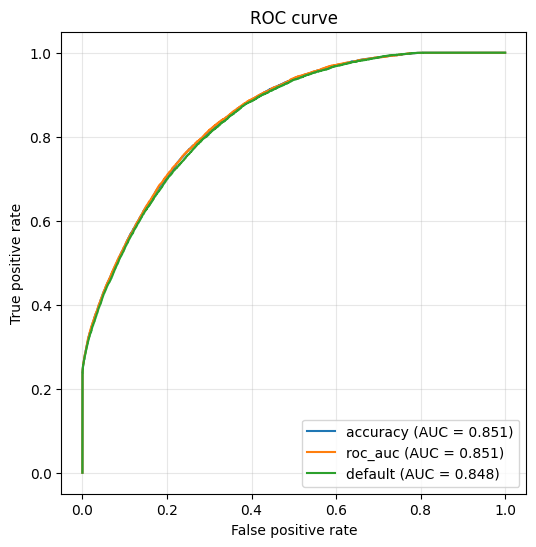

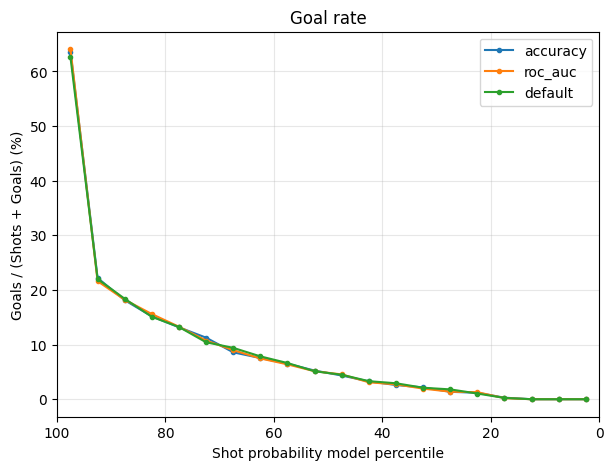

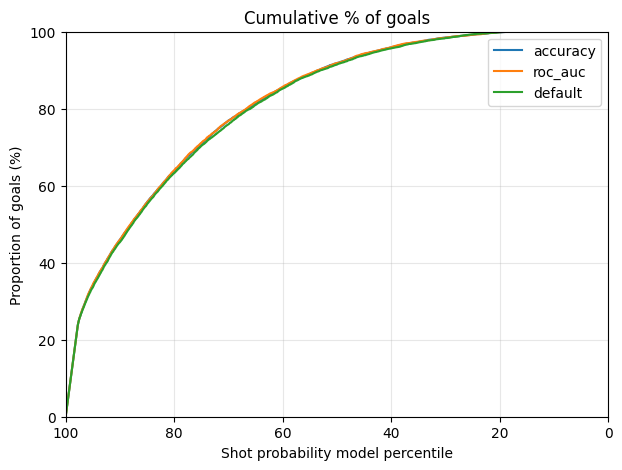

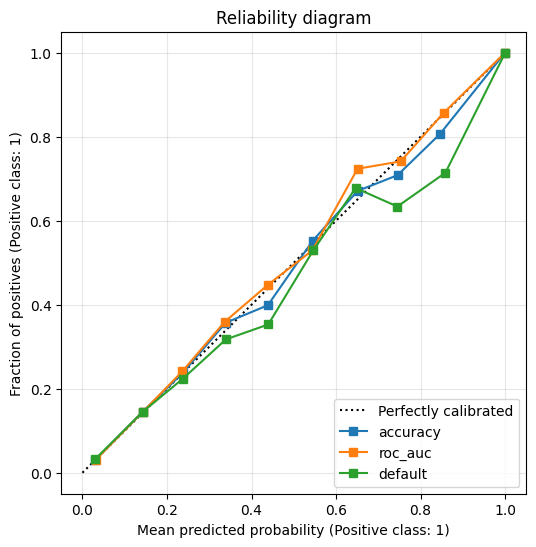

In [45]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()
plot_calibration(y_val,probas)
plt.show()

# Feature Selection

In [ ]:
# Reset probas
probas = {}
# We are starting with 15 features
X_train.shape

(399713, 15)

In [ ]:
# make categorial features to type int

#To change for one-hot encoding
cat_cols = X_train.select_dtypes(include=['category']).columns

for col in cat_cols:
    X_train[col] = X_train[col].astype('category')
    categories = X_train[col].cat.categories

    X_val[col] = pd.Categorical(
        X_val[col],
        categories=categories
    )

    X_train[col] = X_train[col].cat.codes
    X_val[col] = X_val[col].cat.codes

In [66]:
X_train

,game_seconds,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,last_x_coord,last_y_coord,time_from_last,distance_from_last,rebound,change_angle,speed
212500,2839,3,-38.0,17.0,53.758720,18.434949,10,1,-69.0,-22.0,9.0,49.819675,False,0.0,5.535519
7515,1009,1,80.0,19.0,21.023796,64.653824,10,5,38.0,-17.0,18.0,55.317267,False,0.0,3.073181
392993,2963,3,78.0,26.0,28.231188,67.067900,10,0,52.0,-16.0,5.0,49.396356,False,0.0,9.879271
304001,3116,3,-34.0,21.0,58.872744,20.897765,10,4,-57.0,-41.0,6.0,66.128662,False,0.0,11.021444
272878,1441,2,-73.0,-4.0,16.492423,14.036243,10,1,0.0,0.0,6.0,73.109507,False,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449256,693,1,-79.0,23.0,25.079872,66.501434,10,1,-69.0,22.0,9.0,10.049876,False,0.0,1.116653
256728,3362,3,79.0,-6.0,11.661904,30.963757,8,0,54.0,-19.0,16.0,28.178006,False,0.0,1.761125
89320,3599,3,83.0,-36.0,36.496575,80.537678,10,0,66.0,6.0,2.0,45.310043,False,0.0,22.655022
429154,1230,2,57.0,23.0,39.408121,35.706691,10,2,-61.0,40.0,11.0,119.218287,False,0.0,10.838026


In [67]:
# Variance
# Remove features with low variance
selector = VarianceThreshold(0)
X_var0 = selector.fit_transform(X_train,y_train)
print(X_var0.shape)

(399713, 15)


No feature removed with threshold 0

In [ ]:
# Variance
# Remove features with low variance
selector = VarianceThreshold(.8 * (1 - .8))
X_var = selector.fit_transform(X_train,y_train)
print(X_var.shape)
print(selector.get_feature_names_out())

(399713, 14)
[ True  True  True  True  True  True  True  True  True  True  True  True
 False  True  True]
['game_seconds' 'period' 'x_coord' 'y_coord' 'distance' 'angle'
 'shot_type' 'last_event_type' 'last_x_coord' 'last_y_coord'
 'time_from_last' 'distance_from_last' 'change_angle' 'speed']


Feature "rebound" removed with threshold .8 * (1 - .8)

In [ ]:
# For the figures
model_roc.fit(X_var,y_train)
X_val_var = X_val[['game_seconds', 'period', 'x_coord', 'y_coord', 'distance', 'angle',
 'shot_type', 'last_event_type', 'last_x_coord', 'last_y_coord',
 'time_from_last', 'distance_from_last', 'change_angle', 'speed']]
probas['varianceThreshold'] = model_roc.predict_proba(X_val_var)[:, -1]

In [77]:
# Univariate feature selection
selector = SelectKBest(mutual_info_classif,k=5)
X_kbest = selector.fit_transform(X_train,y_train)
X_kbest.shape

cols = X_train.columns[selector.get_support()]
X_kbest = pd.DataFrame(X_kbest,columns=cols,index=X_train.index)
X_kbest

,period,distance,shot_type,rebound,change_angle
212500,3.0,53.758720,10.0,0.0,0.0
7515,1.0,21.023796,10.0,0.0,0.0
392993,3.0,28.231188,10.0,0.0,0.0
304001,3.0,58.872744,10.0,0.0,0.0
272878,2.0,16.492423,10.0,0.0,0.0
...,...,...,...,...,...
449256,1.0,25.079872,10.0,0.0,0.0
256728,3.0,11.661904,8.0,0.0,0.0
89320,3.0,36.496575,10.0,0.0,0.0
429154,2.0,39.408121,10.0,0.0,0.0


In [ ]:
# For the figures
model_roc.fit(X_kbest,y_train)
X_val_kbest = X_val[cols]
probas['selectKBest'] = model_roc.predict_proba(X_val_kbest)[:, -1]

In [80]:
selector = SelectPercentile(mutual_info_classif,percentile=10)
X_perc = selector.fit_transform(X_train,y_train)

cols = X_train.columns[selector.get_support()]
X_perc = pd.DataFrame(X_perc,columns=cols,index=X_train.index)
X_perc

,shot_type,rebound
212500,10.0,0.0
7515,10.0,0.0
392993,10.0,0.0
304001,10.0,0.0
272878,10.0,0.0
...,...,...
449256,10.0,0.0
256728,8.0,0.0
89320,10.0,0.0
429154,10.0,0.0


In [ ]:
# For the figures
model_roc.fit(X_perc,y_train)
X_val_perc = X_val[cols]
probas['selectPercentile'] = model_roc.predict_proba(X_val_perc)[:, -1]

In [83]:
selector = SelectPercentile(mutual_info_classif,percentile=60)
X_perc = selector.fit_transform(X_train,y_train)

cols = X_train.columns[selector.get_support()]
X_perc = pd.DataFrame(X_perc,columns=cols,index=X_train.index)
X_perc

,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,rebound,change_angle
212500,3.0,-38.0,17.0,53.758720,18.434949,10.0,1.0,0.0,0.0
7515,1.0,80.0,19.0,21.023796,64.653824,10.0,5.0,0.0,0.0
392993,3.0,78.0,26.0,28.231188,67.067900,10.0,0.0,0.0,0.0
304001,3.0,-34.0,21.0,58.872744,20.897765,10.0,4.0,0.0,0.0
272878,2.0,-73.0,-4.0,16.492423,14.036243,10.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
449256,1.0,-79.0,23.0,25.079872,66.501434,10.0,1.0,0.0,0.0
256728,3.0,79.0,-6.0,11.661904,30.963757,8.0,0.0,0.0,0.0
89320,3.0,83.0,-36.0,36.496575,80.537678,10.0,0.0,0.0,0.0
429154,2.0,57.0,23.0,39.408121,35.706691,10.0,2.0,0.0,0.0


In [ ]:
# For the figures
model_roc.fit(X_perc,y_train)
X_val_perc = X_val[cols]
probas['selectPercentile60'] = model_roc.predict_proba(X_val_perc)[:, -1]

In [ ]:
# Sequential Feature Selection
sfs = SequentialFeatureSelector(model_roc, tol=0.1)
X_sfs = sfs.fit_transform(X_train, y_train)

cols = X_train.columns[sfs.get_support()]
X_sfs = pd.DataFrame(X_sfs,columns=cols,index=X_train.index)
X_sfs

,game_seconds
212500,2839.0
7515,1009.0
392993,2963.0
304001,3116.0
272878,1441.0
...,...
449256,693.0
256728,3362.0
89320,3599.0
429154,1230.0


In [ ]:
# For the figures
model_roc.fit(X_sfs,y_train)
X_val_sfs = X_val[cols]
probas['sequential'] = model_roc.predict_proba(X_val_sfs)[:, -1]

In [ ]:
# Recursive feature elimination
selector = RFE(model_roc, n_features_to_select=10, step=1)
X_rfe = selector.fit_transform(X_train, y_train)

cols = X_train.columns[selector.get_support()]
X_rfe = pd.DataFrame(X_rfe,columns=cols,index=X_train.index)
X_rfe

,game_seconds,period,distance,angle,shot_type,last_event_type,time_from_last,distance_from_last,rebound,speed
212500,2839.0,3.0,53.758720,18.434949,10.0,1.0,9.0,49.819675,0.0,5.535519
7515,1009.0,1.0,21.023796,64.653824,10.0,5.0,18.0,55.317267,0.0,3.073181
392993,2963.0,3.0,28.231188,67.067900,10.0,0.0,5.0,49.396356,0.0,9.879271
304001,3116.0,3.0,58.872744,20.897765,10.0,4.0,6.0,66.128662,0.0,11.021444
272878,1441.0,2.0,16.492423,14.036243,10.0,1.0,6.0,73.109507,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...
449256,693.0,1.0,25.079872,66.501434,10.0,1.0,9.0,10.049876,0.0,1.116653
256728,3362.0,3.0,11.661904,30.963757,8.0,0.0,16.0,28.178006,0.0,1.761125
89320,3599.0,3.0,36.496575,80.537678,10.0,0.0,2.0,45.310043,0.0,22.655022
429154,1230.0,2.0,39.408121,35.706691,10.0,2.0,11.0,119.218287,0.0,10.838026


In [ ]:
# For the figures
model_roc.fit(X_rfe,y_train)
X_val_rfe = X_val[cols]
probas['RFE'] = model_roc.predict_proba(X_val_rfe)[:, -1]

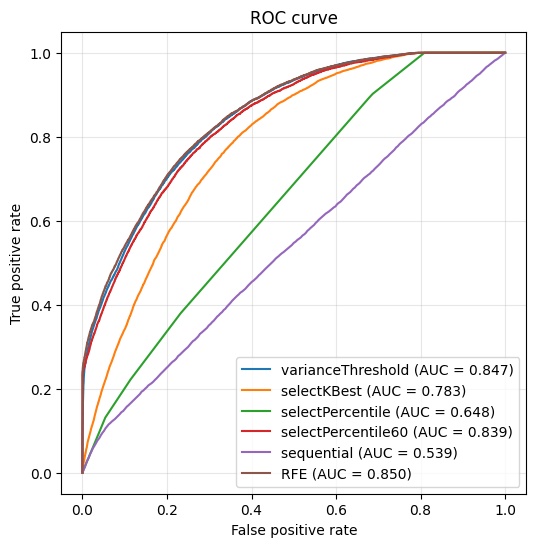

C:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis\ift6758\milestone2\models\plot.py:47: RuntimeWarning: Mean of empty slice.
  goal_rate = [y[bins==b].mean() * 100 for b in range(n_bins)]
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis\.venv\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


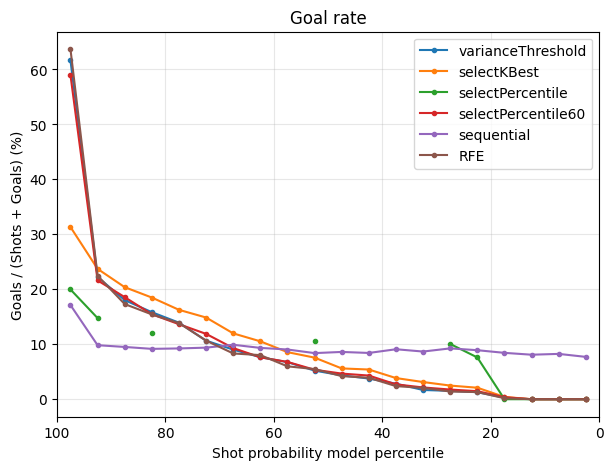

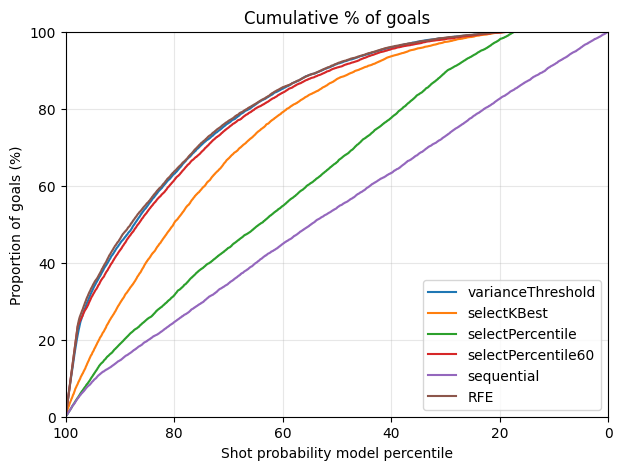

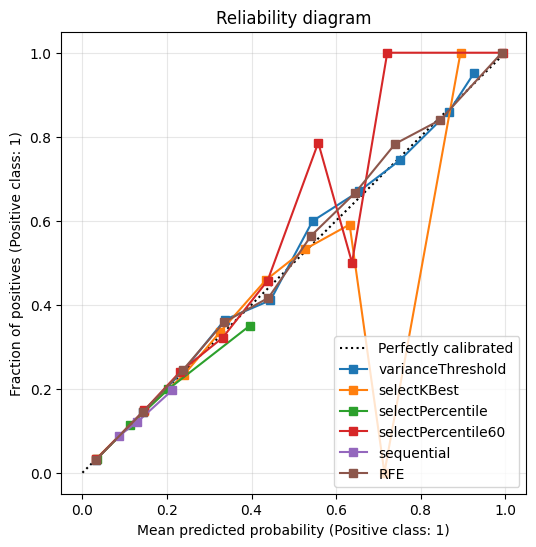

In [92]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()
plot_calibration(y_val,probas)
plt.show()

RFE seems to give the best results

In [ ]:
def selector_rfe(n,model):
    selector = RFE(model, n_features_to_select=n, step=1)
    X_rfe = selector.fit_transform(X_train, y_train)

    cols = X_train.columns[selector.get_support()]
    X_rfe = pd.DataFrame(X_rfe,columns=cols,index=X_train.index)

    model.fit(X_rfe,y_train)
    X_val_rfe = X_val[cols]
    probas['RFE'+str(n)] = model.predict_proba(X_val_rfe)[:, -1]

    return

In [ ]:
# Reset probas
probas = {}

features = 14
while features > 10:
    selector_rfe(features,model_roc)
    features -= 1

In [ ]:
for p in probas.items():
    y_predict = np.where(p[1]>0.5, 1, 0)
    print(p[0])
    print(roc_auc_score(y_val,y_predict))

RFE14
0.6246223781020772
RFE13
0.6247114772087845
RFE12
0.6248462972211093
RFE11
0.6243803309827397


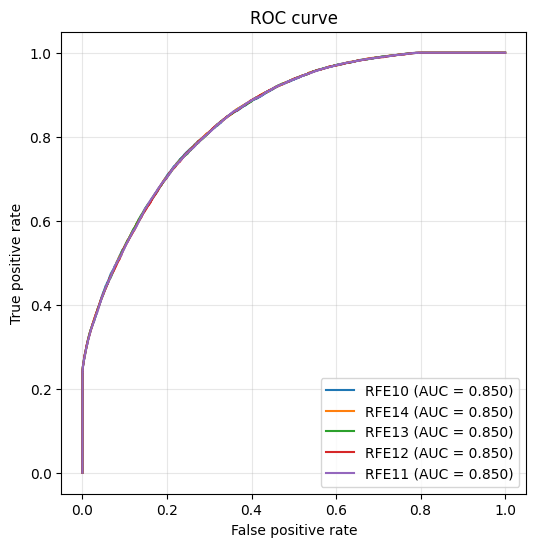

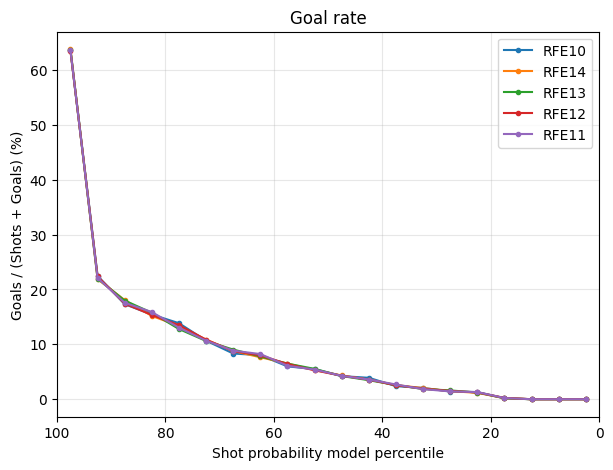

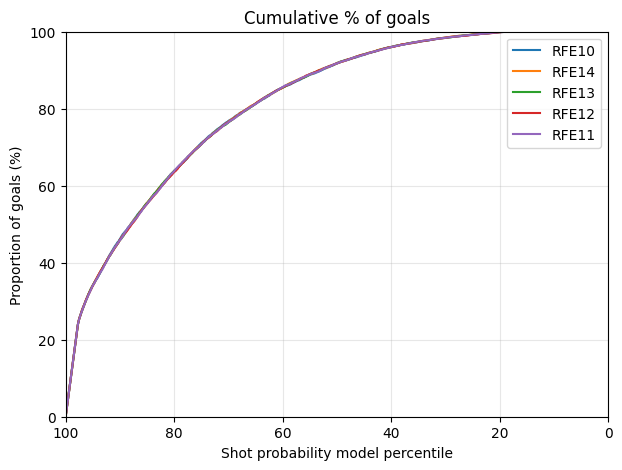

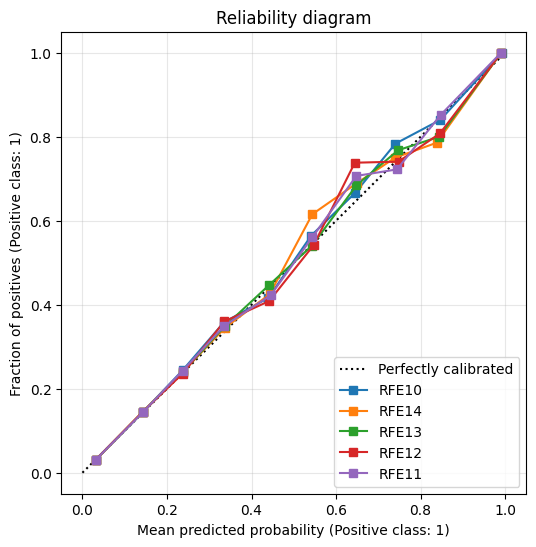

In [105]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()
plot_calibration(y_val,probas)
plt.show()

In [ ]:
# Reset probas
probas = {}

features = 10
while features > 5:
    selector_rfe(features,model_roc)
    features -= 1

In [ ]:
for p in probas.items():
    y_predict = np.where(p[1]>0.5, 1, 0)
    print(p[0])
    print(roc_auc_score(y_val,y_predict))

RFE10
0.6252310570006605
RFE9
0.6250315862727044
RFE8
0.622574025906712
RFE7
0.6228641679984933
RFE6
0.6213480050142469


Highest roc_auc_score for 10 features

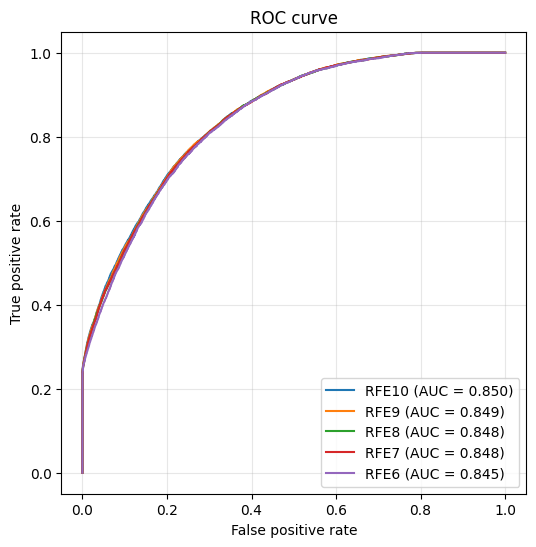

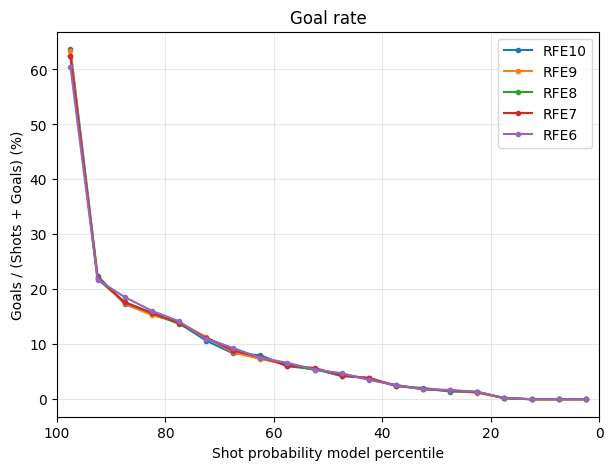

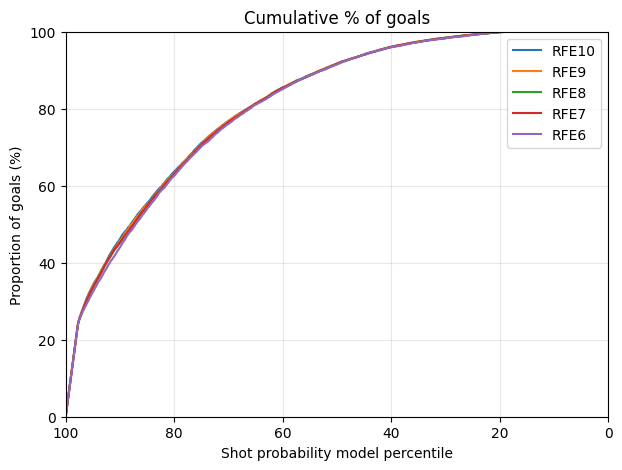

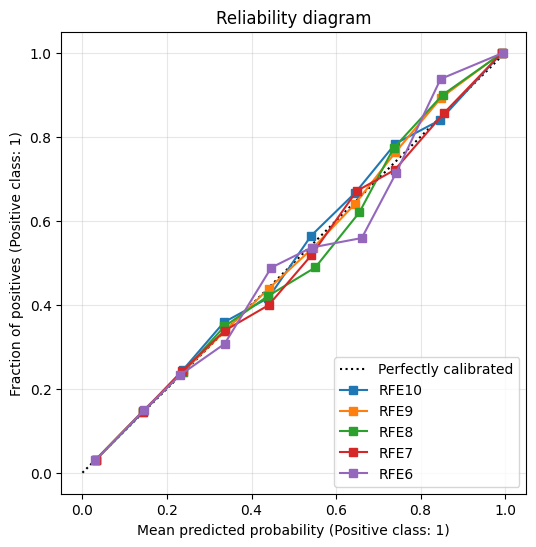

In [108]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()
plot_calibration(y_val,probas)
plt.show()

9 features seems to be the closest to perfect calibration.

## Hyperparameters tuning with the features selected

In [121]:
selector = RFE(model_roc, n_features_to_select=9, step=1)
X_rfe = selector.fit_transform(X_train, y_train)

cols = X_train.columns[selector.get_support()]
X_rfe = pd.DataFrame(X_rfe,columns=cols,index=X_train.index)

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

select_hyper('roc_auc',X_rfe,param_grid,clf)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}
0.8499754643295774


Fitting 5 folds for each of 54 candidates, totalling 270 fits
{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 1.0}
0.8511121149558966